<a href="https://colab.research.google.com/github/ayeshaehsan7/animal-classifier-project/blob/main/animal_classifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
import kagglehub
path = kagglehub.dataset_download("alessiocorrado99/animals10")
print("Downloaded to:", path)

Using Colab cache for faster access to the 'animals10' dataset.
Downloaded to: /kaggle/input/animals10


In [5]:
import os

print("Inside the main folder:", os.listdir(path))

raw = os.path.join(path, "raw-img")
if os.path.exists(raw):
    print("Animal folders found:", os.listdir(raw))
else:
    print("raw-img folder not found")

Inside the main folder: ['translate.py', 'raw-img']
Animal folders found: ['cavallo', 'pecora', 'elefante', 'gatto', 'scoiattolo', 'gallina', 'ragno', 'mucca', 'cane', 'farfalla']


In [6]:
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt

In [7]:
train_data = tf.keras.utils.image_dataset_from_directory(
    raw,
    validation_split=0.2,
    subset="training",
    seed=123,
    image_size=(128, 128),
    batch_size=32
)

val_data = tf.keras.utils.image_dataset_from_directory(
    raw,
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=(128, 128),
    batch_size=32
)

Found 26179 files belonging to 10 classes.
Using 20944 files for training.
Found 26179 files belonging to 10 classes.
Using 5235 files for validation.


In [8]:
class_names = train_data.class_names
print(class_names)
num_classes = len(class_names)
print(num_classes)

['cane', 'cavallo', 'elefante', 'farfalla', 'gallina', 'gatto', 'mucca', 'pecora', 'ragno', 'scoiattolo']
10


In [9]:
train_data = train_data.prefetch(tf.data.AUTOTUNE)
val_data = val_data.prefetch(tf.data.AUTOTUNE)

In [10]:
model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),
    layers.Rescaling(1./255),
    layers.Conv2D(32, (3,3), activation='relu'),
    layers.MaxPooling2D(2,2),
    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D(2,2),
    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D(2,2),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(num_classes, activation='softmax')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       802,880 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 859,850 (3.28 MB)

 Trainable params: 859,850 (3.28 MB)

 Non-trainable params: 0 (0.00 B)

In [11]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [12]:
history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=10
)

Epoch 1/10
655/655 ━━━━━━━━━━━━━━━━━━━━ 101s 141ms/step - accuracy: 0.3832 - loss: 1.7618 - val_accuracy: 0.5093 - val_loss: 1.4185
Epoch 2/10
655/655 ━━━━━━━━━━━━━━━━━━━━ 36s 54ms/step - accuracy: 0.5607 - loss: 1.2914 - val_accuracy: 0.6048 - val_loss: 1.1727
Epoch 3/10
655/655 ━━━━━━━━━━━━━━━━━━━━ 30s 45ms/step - accuracy: 0.6563 - loss: 1.0344 - val_accuracy: 0.6208 - val_loss: 1.1399
Epoch 4/10
655/655 ━━━━━━━━━━━━━━━━━━━━ 30s 46ms/step - accuracy: 0.7129 - loss: 0.8569 - val_accuracy: 0.6346 - val_loss: 1.1329
Epoch 5/10
655/655 ━━━━━━━━━━━━━━━━━━━━ 34s 52ms/step - accuracy: 0.7674 - loss: 0.6877 - val_accuracy: 0.6552 - val_loss: 1.1497
Epoch 6/10
655/655 ━━━━━━━━━━━━━━━━━━━━ 30s 45ms/step - accuracy: 0.8172 - loss: 0.5438 - val_accuracy: 0.6403 - val_loss: 1.3366
Epoch 7/10
655/655 ━━━━━━━━━━━━━━━━━━━━ 41s 44ms/step - accuracy: 0.8627 - loss: 0.4136 - val_accuracy: 0.6332 - val_loss: 1.5054
Epoch 8/10
655/655 ━━━━━━━━━━━━━━━━━━━━ 30s 46ms/step - accuracy: 0.8988 - loss: 0.3035 

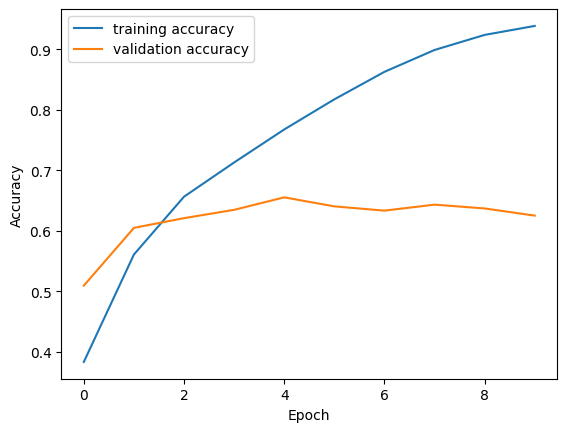

In [13]:
plt.plot(history.history['accuracy'], label='training accuracy')
plt.plot(history.history['val_accuracy'], label='validation accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

In [14]:
data_augmentation = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
])

model2 = models.Sequential([
    layers.Input(shape=(128, 128, 3)),
    data_augmentation,
    layers.Rescaling(1./255),
    layers.Conv2D(32, (3,3), activation='relu'),
    layers.MaxPooling2D(2,2),
    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D(2,2),
    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D(2,2),
    layers.Flatten(),
    layers.Dropout(0.5),
    layers.Dense(64, activation='relu'),
    layers.Dense(num_classes, activation='softmax')
])

model2.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=3, restore_best_weights=True
)

history2 = model2.fit(
    train_data,
    validation_data=val_data,
    epochs=15,
    callbacks=[early_stop]
)

Epoch 1/15
655/655 ━━━━━━━━━━━━━━━━━━━━ 39s 51ms/step - accuracy: 0.3384 - loss: 1.8651 - val_accuracy: 0.4728 - val_loss: 1.5213
Epoch 2/15
655/655 ━━━━━━━━━━━━━━━━━━━━ 37s 56ms/step - accuracy: 0.4905 - loss: 1.4852 - val_accuracy: 0.5287 - val_loss: 1.3882
Epoch 3/15
655/655 ━━━━━━━━━━━━━━━━━━━━ 32s 48ms/step - accuracy: 0.5521 - loss: 1.3234 - val_accuracy: 0.4837 - val_loss: 1.5526
Epoch 4/15
655/655 ━━━━━━━━━━━━━━━━━━━━ 46s 56ms/step - accuracy: 0.5856 - loss: 1.2254 - val_accuracy: 0.6011 - val_loss: 1.1874
Epoch 5/15
655/655 ━━━━━━━━━━━━━━━━━━━━ 32s 48ms/step - accuracy: 0.6059 - loss: 1.1686 - val_accuracy: 0.6017 - val_loss: 1.1465
Epoch 6/15
655/655 ━━━━━━━━━━━━━━━━━━━━ 42s 50ms/step - accuracy: 0.6206 - loss: 1.1098 - val_accuracy: 0.6155 - val_loss: 1.1256
Epoch 7/15
655/655 ━━━━━━━━━━━━━━━━━━━━ 36s 55ms/step - accuracy: 0.6393 - loss: 1.0645 - val_accuracy: 0.6021 - val_loss: 1.1357
Epoch 8/15
655/655 ━━━━━━━━━━━━━━━━━━━━ 31s 48ms/step - accuracy: 0.6446 - loss: 1.0501 - 

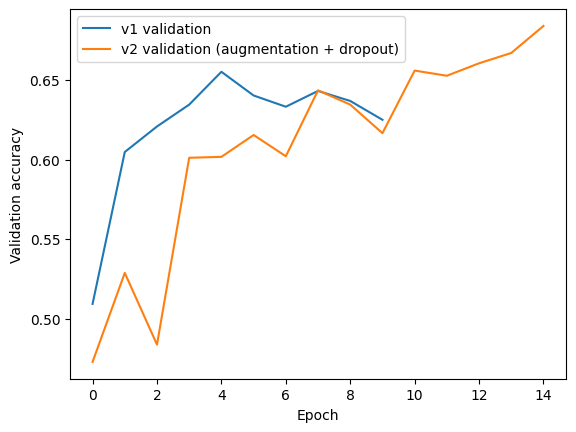

In [15]:
plt.plot(history.history['val_accuracy'], label='v1 validation')
plt.plot(history2.history['val_accuracy'], label='v2 validation (augmentation + dropout)')
plt.xlabel('Epoch')
plt.ylabel('Validation accuracy')
plt.legend()
plt.show()